#### Khai báo các thư viên cần thiết

In [24]:
import os
import datetime  as dt
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

import tensorflow as tf

In [3]:
# Path
BASE_DIR = os.path.dirname(os.path.abspath('__file__'))
PARENT_DIR = os.path.dirname(BASE_DIR)
DATASET_DIR = "plantvillage_dataset/color"
METADATA_DIR = "plantvillage_dataset/csv/cleaned_metadata.csv"

#### Load metadata

In [4]:
# load dataset
df = pd.read_csv(os.path.join(PARENT_DIR, METADATA_DIR))
df.head(3)

,path,name,class,plant,disease,width,height,mode,mean_r,mean_g,mean_b,brightness,contrast,sharpness,file_size(KB),file_hash
0,d:\2026-2027\computer-vision\plantvillage_data...,00075aa8-d81a-4184-8541-b692b78d398a___FREC_Sc...,Apple___Apple_scab,Apple,Apple_scab,256,256,RGB,110.662399,130.183029,119.862732,123.143341,39.137342,12.194016,9616,841d0bf56e5ab96bb96b0953c49eb31a
1,d:\2026-2027\computer-vision\plantvillage_data...,01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Sc...,Apple___Apple_scab,Apple,Apple_scab,256,256,RGB,84.160263,97.555771,103.142639,94.179001,26.618654,14.173828,10108,b864c04c6195b89d7d7555311dbc3ca4
2,d:\2026-2027\computer-vision\plantvillage_data...,01f3deaa-6143-4b6c-9c22-620a46d8be04___FREC_Sc...,Apple___Apple_scab,Apple,Apple_scab,256,256,RGB,92.535965,125.726334,116.025253,114.686539,30.973891,20.961884,12005,2265a73c77faf5468e8b90e6dd67897c


In [5]:
len(df['class'].unique())

38

#### Chia stratified 70/15/15

In [6]:
data = df[['path', 'plant', 'disease', 'class']]
data.head()

,path,plant,disease,class
0,d:\2026-2027\computer-vision\plantvillage_data...,Apple,Apple_scab,Apple___Apple_scab
1,d:\2026-2027\computer-vision\plantvillage_data...,Apple,Apple_scab,Apple___Apple_scab
2,d:\2026-2027\computer-vision\plantvillage_data...,Apple,Apple_scab,Apple___Apple_scab
3,d:\2026-2027\computer-vision\plantvillage_data...,Apple,Apple_scab,Apple___Apple_scab
4,d:\2026-2027\computer-vision\plantvillage_data...,Apple,Apple_scab,Apple___Apple_scab


In [7]:
# chia cho train 70%, temp 30%
train, temp = train_test_split(
    data,
    test_size = 0.3,
    random_state = 425,
    shuffle=True,
    stratify = data['class']
)

In [8]:
train.head(5)

,path,plant,disease,class
44081,d:\2026-2027\computer-vision\plantvillage_data...,Tomato,Septoria_leaf_spot,Tomato___Septoria_leaf_spot
10798,d:\2026-2027\computer-vision\plantvillage_data...,Grape,Black_rot,Grape___Black_rot
32142,d:\2026-2027\computer-vision\plantvillage_data...,Soybean,healthy,Soybean___healthy
40819,d:\2026-2027\computer-vision\plantvillage_data...,Tomato,healthy,Tomato___healthy
44122,d:\2026-2027\computer-vision\plantvillage_data...,Tomato,Septoria_leaf_spot,Tomato___Septoria_leaf_spot


In [9]:
temp.head()

,path,plant,disease,class
15113,d:\2026-2027\computer-vision\plantvillage_data...,Orange,Haunglongbing_(Citrus_greening),Orange___Haunglongbing_(Citrus_greening)
26105,d:\2026-2027\computer-vision\plantvillage_data...,Potato,Early_blight,Potato___Early_blight
4786,d:\2026-2027\computer-vision\plantvillage_data...,Cherry,healthy,Cherry_(including_sour)___healthy
34058,d:\2026-2027\computer-vision\plantvillage_data...,Squash,Powdery_mildew,Squash___Powdery_mildew
22421,d:\2026-2027\computer-vision\plantvillage_data...,Peach,healthy,Peach___healthy


In [10]:
# lay 30% temp chia val50% - test 50%
val, test = train_test_split(
    temp,
    test_size= 0.5,
    random_state= 425,
    shuffle = True,
    stratify= temp['class']
)

In [11]:
val.head()

,path,plant,disease,class
7626,d:\2026-2027\computer-vision\plantvillage_data...,Corn,Common_rust_,Corn_(maize)___Common_rust_
9768,d:\2026-2027\computer-vision\plantvillage_data...,Corn,Northern_Leaf_Blight,Corn_(maize)___Northern_Leaf_Blight
18730,d:\2026-2027\computer-vision\plantvillage_data...,Orange,Haunglongbing_(Citrus_greening),Orange___Haunglongbing_(Citrus_greening)
30061,d:\2026-2027\computer-vision\plantvillage_data...,Soybean,healthy,Soybean___healthy
1300,d:\2026-2027\computer-vision\plantvillage_data...,Apple,Cedar_apple_rust,Apple___Cedar_apple_rust


In [12]:
# So luong mau cua cac tap sau khi chia 70/15/15
total = len(data)

print(f"Train: {len(train):,} ({len(train) / total:.2%})")
print(f"Validation: {len(val):,} ({len(val) / total:.2%})")
print(f"Test: {len(test):,} ({len(test) / total:.2%})")
print(f"Total: {total:,}")

Train: 37,998 (70.00%)
Validation: 8,143 (15.00%)
Test: 8,143 (15.00%)
Total: 54,284


In [13]:
# kiem tra nhan cua cac tap co du cac nhan khong
print("Train classes:", train["class"].nunique())
print("Validation classes:", val["class"].nunique())
print("Test classes:", test["class"].nunique())

Train classes: 38
Validation classes: 38
Test classes: 38


In [14]:
# Kiem tra su phan bo class sau chia
train_dist = train["class"].value_counts(normalize=False)
val_dist = val["class"].value_counts(normalize=False)
test_dist = test["class"].value_counts(normalize=False)

distribution_check = pd.DataFrame({
    "Train": train_dist,
    "Validation": val_dist,
    "Test": test_dist
})

distribution_check

,Train,Validation,Test
class,,,
Apple___Apple_scab,441,94,95
Apple___Black_rot,435,93,93
Apple___Cedar_apple_rust,193,41,41
Apple___healthy,1147,246,245
Blueberry___healthy,1051,225,226
Cherry_(including_sour)___Powdery_mildew,736,158,158
Cherry_(including_sour)___healthy,598,128,128
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,359,77,77
Corn_(maize)___Common_rust_,834,179,179


In [15]:
# kiem tra Leakage
train_paths = set(train["path"])
val_paths = set(val["path"])
test_paths = set(test["path"])

print("Train ∩ Validation:", len(train_paths & val_paths))
print("Train ∩ Test:", len(train_paths & test_paths))
print("Validation ∩ Test:", len(val_paths & test_paths))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [17]:
# Dung LabelEncoder
label_encoder = LabelEncoder()
train["label"] = label_encoder.fit_transform(train['class'])
val["label"] = label_encoder.transform(val["class"])
test["label"] = label_encoder.transform(test["class"])

In [18]:
# luu cac file train, val, test vao csv
train.to_csv(os.path.join(PARENT_DIR, "plantvillage_dataset/csv/train.csv"), index=False)
print(f"Save success file train.csv. Path: {os.path.join(PARENT_DIR, 'plantvillage_dataset/csv/train.csv')}.")
val.to_csv(os.path.join(PARENT_DIR, "plantvillage_dataset/csv/val.csv"), index=False)
print(f"Save success file val.csv. Path: {os.path.join(PARENT_DIR, 'plantvillage_dataset/csv/val.csv')}.")
test.to_csv(os.path.join(PARENT_DIR, "plantvillage_dataset/csv/test.csv"), index=False)
print(f"Save success file test.csv. Path: {os.path.join(PARENT_DIR, 'plantvillage_dataset/csv/test.csv')}.")


Save success file train.csv. Path: d:\2026-2027\computer-vision\plantvillage_dataset/csv/train.csv.
Save success file val.csv. Path: d:\2026-2027\computer-vision\plantvillage_dataset/csv/val.csv.
Save success file test.csv. Path: d:\2026-2027\computer-vision\plantvillage_dataset/csv/test.csv.


#### Thiết lập preprocessing.


In [26]:
import tensorflow as tf

# config
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
SEED = 425

#### Thiết lập augmentation chỉ cho Train.


In [27]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip(
        mode="horizontal_and_vertical",
        seed=SEED
    ),

    tf.keras.layers.RandomRotation(
        factor=30 / 360,
        seed=SEED
    ),

    tf.keras.layers.RandomCrop(
        height=200,
        width=200,
        seed=SEED
    ),

    tf.keras.layers.Resizing(
        height=224,
        width=224
    ),

    tf.keras.layers.RandomBrightness(
        factor=0.2,
        seed=SEED
    ),

    tf.keras.layers.RandomContrast(
        factor=0.2,
        seed=SEED
    )
])

#### Chuẩn bị pipeline cho model.

In [19]:
PATH = os.path.join(PARENT_DIR, 'plantvillage_dataset/csv/')
train_df = pd.read_csv(os.path.join(PATH, 'train.csv'))
val_df = pd.read_csv(os.path.join(PATH, 'val.csv'))
test_df = pd.read_csv(os.path.join(PATH, 'test.csv'))

In [20]:
train_df.head()

,path,plant,disease,class,label
0,d:\2026-2027\computer-vision\plantvillage_data...,Tomato,Septoria_leaf_spot,Tomato___Septoria_leaf_spot,32
1,d:\2026-2027\computer-vision\plantvillage_data...,Grape,Black_rot,Grape___Black_rot,11
2,d:\2026-2027\computer-vision\plantvillage_data...,Soybean,healthy,Soybean___healthy,24
3,d:\2026-2027\computer-vision\plantvillage_data...,Tomato,healthy,Tomato___healthy,37
4,d:\2026-2027\computer-vision\plantvillage_data...,Tomato,Septoria_leaf_spot,Tomato___Septoria_leaf_spot,32


In [21]:
class_names = label_encoder.classes_
class_names

array(['Apple___Apple_scab', 'Apple___Black_rot',
       'Apple___Cedar_apple_rust', 'Apple___healthy',
       'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew',
       'Cherry_(including_sour)___healthy',
       'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
       'Corn_(maize)___Common_rust_',
       'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy',
       'Grape___Black_rot', 'Grape___Esca_(Black_Measles)',
       'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy',
       'Orange___Haunglongbing_(Citrus_greening)',
       'Peach___Bacterial_spot', 'Peach___healthy',
       'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy',
       'Potato___Early_blight', 'Potato___Late_blight',
       'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy',
       'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch',
       'Strawberry___healthy', 'Tomato___Bacterial_spot',
       'Tomato___Early_blight', 'Tomato___Late_blight',
   

In [22]:
def load_image(path, label):
    """
    Đọc ảnh từ đường dẫn, giải mã ảnh RGB và chuẩn bị nhãn tương ứng.

    Parameters:
        path (tf.Tensor): Đường dẫn đến file ảnh.
        label (tf.Tensor): Nhãn số nguyên của ảnh.

    Returns:
        tuple: Ảnh đã đọc và nhãn tương ứng.
    """
    image = tf.io.read_file(path)
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(
        image,
        tf.float32
    )

    return image, label

In [28]:
train_dataset = tf.data.Dataset.from_tensor_slices(
    (
        train_df["path"].values,
        train_df["label"].values
    )
)

train_dataset = train_dataset.shuffle(
    buffer_size=len(train_df),
    seed=SEED,
    reshuffle_each_iteration=True
)

train_dataset = train_dataset.map(
    load_image,
    num_parallel_calls=AUTOTUNE
)

train_dataset = train_dataset.map(
    lambda image, label: (
        data_augmentation(image, training=True),
        label
    ),
    num_parallel_calls=AUTOTUNE
)

train_dataset = train_dataset.batch(BATCH_SIZE)

train_dataset = train_dataset.prefetch(AUTOTUNE)

In [29]:
val_dataset = tf.data.Dataset.from_tensor_slices(
    (
        val_df["path"].values,
        val_df["label"].values
    )
)

val_dataset = val_dataset.map(
    load_image,
    num_parallel_calls=AUTOTUNE
)

val_dataset = val_dataset.batch(
    BATCH_SIZE
)

val_dataset = val_dataset.prefetch(
    AUTOTUNE
)

In [30]:
test_dataset = tf.data.Dataset.from_tensor_slices(
    (
        test_df["path"].values,
        test_df["label"].values
    )
)

test_dataset = test_dataset.map(
    load_image,
    num_parallel_calls=AUTOTUNE
)

test_dataset = test_dataset.batch(BATCH_SIZE)

test_dataset = test_dataset.prefetch(AUTOTUNE)

In [31]:
images, labels = next(iter(train_dataset))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

Image shape: (32, 224, 224, 3)
Label shape: (32,)
Image dtype: <dtype: 'float32'>
Label dtype: <dtype: 'int64'>


In [32]:
images, labels = next(iter(val_dataset))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

Image shape: (32, 224, 224, 3)
Label shape: (32,)
Image dtype: <dtype: 'float32'>
Label dtype: <dtype: 'int64'>


In [33]:
images, labels = next(iter(test_dataset))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

Image shape: (32, 224, 224, 3)
Label shape: (32,)
Image dtype: <dtype: 'float32'>
Label dtype: <dtype: 'int64'>


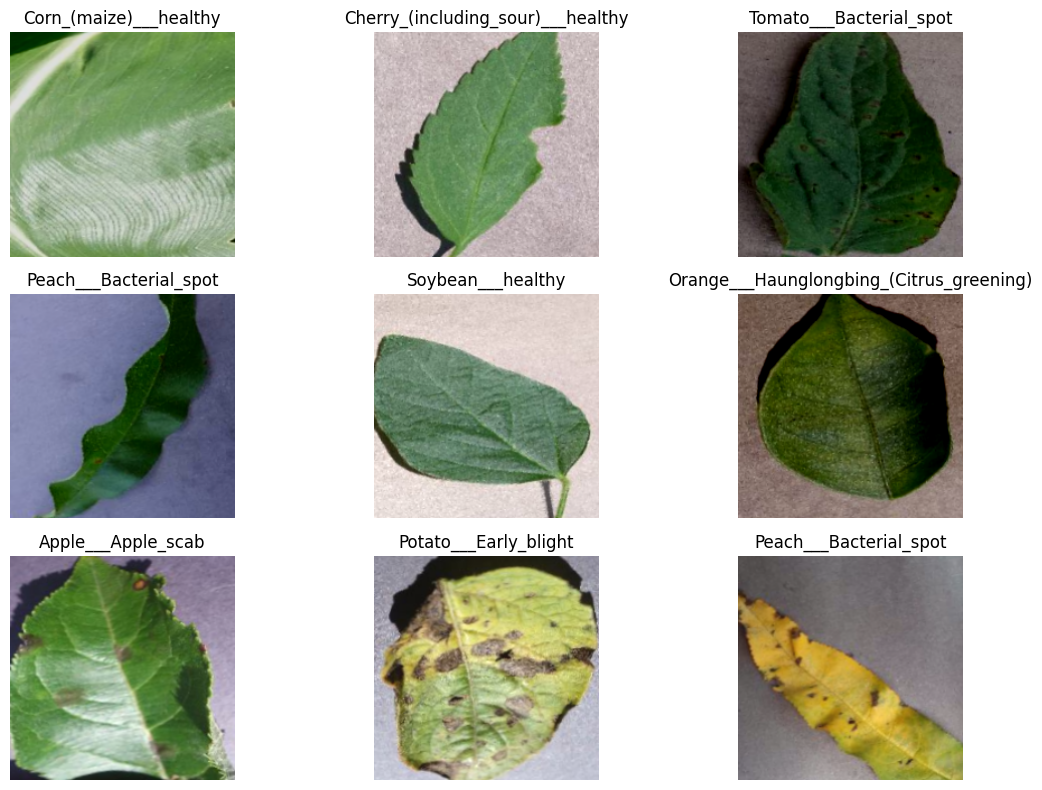

In [34]:
images, labels = next(iter(train_dataset))

plt.figure(figsize=(12, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(
        tf.cast(images[i], tf.uint8)
    )
    plt.title(class_names[labels[i].numpy()])
    plt.axis("off")

plt.tight_layout()
plt.show()